In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set display options for clarity
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
sns.set_theme(style="whitegrid")

---
## 1. Executive Summary
This case study analyzes 100k+ historical transactions (2016–2018) from Olist, a leading Brazilian e-commerce technology platform. Adopting a Marketplace Financial Model, this project evaluates GMV structure, platform commission revenues, and variable fulfillment costs to determine how much of each transaction Olist retains after payment processing fees and freight subsidies, and which product categories erode that margin.

### Key Analytical Findings
* **Baseline Commission Model (7.0%):** Olist converts **BRL 15,222,078.06** of GMV into **BRL 913,554.00** of net revenue (a **6.00% take rate**) and **BRL 202,274.75** of contribution margin (**22.14%** of net revenue).
* **Cost Burden:** Payment gateway fees (**BRL 382,922.08**) and cross-state freight subsidies (**BRL 328,349.42**) absorb **77.86%** of net revenue.
* **Category-Dynamic Commission Model:** Net revenue falls to **BRL 600,947.82** (a **3.95% take rate**) and contribution margin turns negative at **BRL -110,328.05** (**-18.36%** of net revenue).
* **Drivers of Profitability:** Category profitability is driven by the **freight-to-revenue ratio** (correlation of **-0.85** with CM margin) rather than absolute freight cost (correlation of **0.04**).
* **Breakeven Threshold:** The platform-wide breakeven AOV at a 7% take rate is **BRL 43.17**.

### Strategic Recommendations
1. **Review commission structures category by category**, since the dynamic rate model produces a negative contribution margin.
2. **Restrict freight subsidies** on orders below the **BRL 43.00** breakeven threshold and cap subsidies on bulky categories such as furniture.
3. **Require bundling or multi-packs** in micro-order categories such as electronics accessories, flowers, and hygiene products.
4. **Review payment gateway costs**, the largest variable cost at **BRL 2.51 per BRL 100.00 of GMV**.
5. **Protect and grow high-margin categories** such as Watches & Gifts, Health & Beauty, and Small Appliances through brand defense, subscriptions, and margin-aware search ranking.

---
## 2. Business Framework & Financial Assumptions

### 2.1 Analytical Perspective
This report adopts a **Marketplace Platform Perspective** rather than a direct retailer perspective. Olist operates as a master-merchant aggregator that lists long-tail sellers' catalogs on host marketplaces such as Mercado Livre and Amazon Brasil, so the primary focus is evaluating Olist's Platform Take-Rate and unit economics across transaction streams, without taking inventory ownership or direct product COGS into account.

### 2.2 Metric Definitions & Financial Logic
| Metric | Financial Formula | Description & Business Context |
| :--- | :--- | :--- |
| **Gross Merchandise Value (GMV)** | Price + Freight Value | Total customer expenditure processed on the platform (Top-line volume, not platform revenue). |
| **Platform Net Revenue** | Platform Commission Rate (7%) × Price | Actual earnings realized by the platform via merchant commissions. |
| **Freight Subsidy (Fulfillment Cost)** | Freight Value × 20% on cross-state orders (`customer_state` ≠ `seller_state`) | Logistics cost co-funded by the platform to stimulate long-distance conversion; no subsidy applies to same-state orders. |
| **Variable Operating Costs** | Payment Gateway Fee (2%) (`PG_cost`) | Direct processing fees incurred per successful order transaction. |
| **Contribution Margin (CM)** | Net Revenue - Payment Gateway Fees - Freight Subsidies | Core profit margin available to cover platform fixed operating expenses and R&D. |
| **Platform Take-Rate** | (Net Revenue / GMV) × 100% | Measures the platform's monetization efficiency relative to total processed transaction volume. |

---
## 3. Data & Methodology Overview

### 3.1 Data Sources
The dataset is sourced from the Kaggle Brazilian E-Commerce (Olist) Dataset, comprising 9 relational tables covering 100k+ orders from 2016 to 2018:
| No | File Name | Description & Primary Key |
| :--- | :--- | :--- |
| 1 | `olist_customers_dataset.csv` | Customer location and demographic data (`customer_id`) |
| 2 | `olist_geolocation_dataset.csv` | Brazilian zip code location coordinates (`geolocation_zip_code_prefix`) |
| 3 | `olist_order_items_dataset.csv` | Line-item transaction details, price, and freight (`order_id`, `product_id`) |
| 4 | `olist_order_payments_dataset.csv` | Payment methods, installments, and payment value (`order_id`) |
| 5 | `olist_order_reviews_dataset.csv` | Customer review scores and response timelines (`review_id`, `order_id`) |
| 6 | `olist_orders_dataset.csv` | Core order log and delivery timestamps (`order_id`, `customer_id`) |
| 7 | `olist_products_dataset.csv` | Product dimensions and weight specifications (`product_id`) |
| 8 | `olist_sellers_dataset.csv` | Merchant location and seller log (`seller_id`) |
| 9 | `product_category_name_translation.csv` | Portuguese to English category translation lookup table |

### 3.2 Analytical Toolkit & Technology Stack
* **Data Extraction, Transformation & Aggregation (ETL):** SQL (PostgreSQL via DBeaver / pgAdmin) — Used for multi-table JOINs, data cleaning, and aggregating transaction-level data into P&L summaries.
* **Data Modeling & Visualization:** Power BI for interactive executive P&L dashboards and Star-Schema modeling; Python for exploratory visualization, correlation profiling, and financial scenario modeling.
* **Statistical Analysis:** DAX, SQL Window Functions, Python (`NumPy`, `Statsmodels`) — Used for Take-Rate calculations, contribution margin segmentation, and trend projections.

---
## 4. Data Cleaning and Manipulation Log

### 4.1 Filtering on Delivered Transactions
* **Discovery:** The `order_status` field contains eight values: `delivered`, `shipped`, `canceled`, `unavailable`, `approved`, `invoiced`, `processing`, and `created`. Unfulfilled and canceled statuses contain missing fulfillment dates and zero-revenue records.
* **Action & Justification:** Restrict the primary financial modeling dataset strictly to transactions where `order_status = 'delivered'` (~96.5% of total orders). Under IFRS 15 / ASC 606 (Revenue from Contracts with Customers), revenue can only be recognized when performance obligations are fully satisfied.

### 4.2 Missing Category Values in `olist_products_dataset`
* **Discovery:** The `olist_products_dataset` contains missing (NULL) values in the `product_category_name` column.
* **Action:** Imputed missing product category values by replacing NULL records with the string `'unknown'`.

In [ ]:
```sql
SELECT 
    product_id, 
    COALESCE(product_category_name, 'unknown') AS product_category_name_clean
FROM olist_products_dataset;
```

* **Justification:** Preserves order records during category-level aggregations and JOIN operations. Assigning unclassified products to an explicit 'unknown' category prevents silent row loss during inner joins with sales and logistics tables, ensuring overall revenue and order volume totals remain complete.

### 4.3 Dynamic Translation Fallback & NULL Imputation
* **Discovery:** Missing English translations (pc_gamer) and untranslated Portuguese edge cases (portateis_cozinha_e_preparadores_de_alimentos), along with NULL category values in olist_products_dataset.
* **Action:** Executed a FULL JOIN using nested COALESCE statements to dynamically assign 'unknown' to missing category values without permanently altering the underlying raw dataset.
* **Justification:** Dynamic imputation preserves raw data integrity while ensuring 100% row coverage. Grouping unassigned items into 'unknown' prevents NULL values from breaking downstream GROUP BY category aggregations and executive dashboards.


In [ ]:
sql```
SELECT DISTINCT  
    COALESCE(pcnt.product_category_name, opd.product_category_name, 'unknown') AS product_category_name_A,
    CASE 
        WHEN opd.product_category_name = 'portateis_cozinha_e_preparadores_de_alimentos' 
            THEN 'kitchen_portables_and_food_preparers'
        ELSE COALESCE(pcnt.product_category_name_english, opd.product_category_name, 'unknown')
    END AS product_category_name_english_A
FROM olist_products_dataset opd 
FULL JOIN product_category_name_translation pcnt 
    ON opd.product_category_name = pcnt.product_category_name
WHERE COALESCE(pcnt.product_category_name, opd.product_category_name) IS NOT NULL
```

### 4.4 Anomaly Assessment: Inverse Carrier Scan Timestamps

* **Discovery:** Identified instances in olist_orders_dataset where order_delivered_carrier_date occurred after order_delivered_customer_date (order_delivered_carrier_date > order_delivered_customer_date).
* **Action:** Retained all records without modification.
* **Justification:** The downstream analysis focuses on overall order lifecycle metrics (e.g., total delivery time from purchase to customer, overall delivery performance vs. estimated date) rather than mid-stage carrier handoff duration. Because no carrier-specific transit metrics are computed, these scan timestamp inversions do not affect the findings or financial accuracy.


---
## 5. Data Integration & Master Merge Pipeline
The objective of this master merge pipeline is to consolidate transactional, customer, seller, product, and payment datasets into a single unified row-level table at the `order_item_id` grain. This table powers both realized P&L calculations (IFRS 15 compliance) and operational cost allocation & loss exposure models.

### 5.1 Technical Integration & Grain Control Architecture
To ensure analytical integrity and prevent financial duplication, the join schema adheres to three strict structural rules:
* **Primary Grain Maintenance:** The query operates strictly at the `order_id + order_item_id` level. Joining directly to raw payment logs would trigger a fan-out bug due to split payments (multi-card/voucher orders).
* **Payment Pre-Aggregation:** Payment acquirer processing fees (2.0% on debit, credit card, and boleto transactions) are pre-aggregated via the Common Table Expression (`PG_fees_count`) at the `order_id` level before performing a `LEFT JOIN`. Because the master table operates at the `order_item_id` grain, each order-level fee is allocated to its line items in proportion to each item's share of order GMV (`price + freight_value`), so that a multi-item order's fee is counted once rather than repeated on every item row.
* **Dual-Track Analytical Framework:**
  * **Track A (Baseline P&L):** Filters for `order_status = 'delivered'` to isolate realized revenues under IFRS 15 / ASC 606 standards.
  * **Track B (Operational Risk & Loss Model):** Evaluates unfulfilled, stale, and late-delivered orders to calculate sunk payment fees and SLA freight penalty exposures.

### 5.2 Entity Relationship & Merge Mapping
| Source Dataset | Primary / Foreign Key | Join Type | Integration Purpose |
| :--- | :--- | :--- | :--- |
| `olist_order_items_dataset` (`ooid`) | `order_id`, `product_id`, `seller_id` | Base Table | Sets primary grain; provides item price and `freight_value`. |
| `olist_orders_dataset` (`ood`) | `order_id` | INNER JOIN | Provides status lifecycle and fulfillment SLA timestamps. |
| `olist_products_dataset` (`opd`) | `product_id` | INNER JOIN | Links native product category names. |
| `Clean_pcnt` (`cp`) | `product_category_name_a` | INNER JOIN | Maps Portuguese categories to translated English categories. |
| `olist_customers_dataset` (`ocd`) | `customer_id` | INNER JOIN | Extracts buyer location (`customer_state`) for cross-state logistics. |
| `olist_sellers_dataset` (`osd`) | `seller_id` | INNER JOIN | Extracts origin location (`seller_state`) for cross-state logistics. |
| `PG_fees_count` (`pfc` CTE) | `order_id` | LEFT JOIN | Attaches pre-aggregated 2% Payment Gateway transaction fees. |

---
## 5.3 Baseline Master Data Pipeline (Delivered Realized P&L)
*Note: The script below translates the baseline SQL P&L extraction query into an optimized Pandas pipeline matching the IFRS 15 / ASC 606 realized revenue standard.*



In [ ]:
SQL```
-- =============================================================================
-- Section 5.3: Data Integration & Master Merge Pipeline (Delivered Baseline P&L)
-- Grain: order_id + order_item_id
-- Framework: IFRS 15 / ASC 606 Realized Revenue Standard
-- =============================================================================

WITH PG_fees_count AS (
    -- Pre-aggregate payment gateway fees per order to eliminate 1:N fan-out bugs
    SELECT
        order_id,
        SUM(
            CASE
                WHEN payment_type IN ('boleto', 'debit_card', 'credit_card')
                THEN payment_value * 0.02
                ELSE 0
            END
        ) AS PG_fees
    FROM public.olist_order_payments_dataset
    GROUP BY order_id
)
SELECT 
    ooid.order_id,
    ooid.product_id,
    cp.product_category_name_english_a,
    
    -- Fulfillment SLA Timestamps
    ooid.shipping_limit_date,
    ood.order_approved_at,
    ood.order_delivered_carrier_date,
    ood.order_delivered_customer_date,
    ood.order_estimated_delivery_date,
    
    -- Late Delivery SLA Breach Indicator
    CASE 
        WHEN ood.order_estimated_delivery_date < ood.order_delivered_customer_date
        THEN 1
        ELSE 0
    END AS late_delivered,

    -- Top-Line Volume Metrics
    ooid.price AS Revenue, 
    ooid.freight_value,
    (ooid.price + ooid.freight_value) AS GMV,

    -- Top-Line Realized Platform Take-Rate Revenue (7% Commission)
    ROUND(CAST(ooid.price * 0.07 AS numeric), 2) AS Net_revenue,

    -- Payment Processing Cost Allocation
    COALESCE(ROUND(CAST(pfc.PG_fees AS numeric), 2), 0.00) AS PG_fees,

    -- Logistics Friction Identification & Freight Subsidy (20% Cross-State Rate)
    CASE 
        WHEN ocd.customer_state <> osd.seller_state
        THEN ROUND(CAST(ooid.freight_value * 0.20 AS numeric), 2)
        ELSE 0.00
    END AS freight_subsidy,

    -- Contribution Margin (CM) Calculation: Net Revenue - Freight Subsidy - Allocated Gateway Fee
    ROUND(
        CAST(
            (ooid.price * 0.07) - 
            (CASE 
                WHEN ocd.customer_state <> osd.seller_state
                THEN ooid.freight_value * 0.20 
                ELSE 0
            END) - 
            COALESCE(pfc.PG_fees, 0)
        AS numeric), 2
    ) AS CM,

    -- Unit Economics Efficiency Metric (Take Rate % against GMV)
    ROUND(
        CAST(
            (ooid.price * 0.07) / NULLIF((ooid.price + ooid.freight_value), 0) 
        AS numeric), 4
    ) AS Platform_take_rate

FROM olist_order_items_dataset ooid
INNER JOIN olist_orders_dataset ood ON ooid.order_id = ood.order_id
INNER JOIN olist_products_dataset opd ON ooid.product_id = opd.product_id
INNER JOIN "Clean_pcnt" cp ON opd.product_category_name = cp.product_category_name_a
INNER JOIN olist_customers_dataset ocd ON ood.customer_id = ocd.customer_id
INNER JOIN olist_sellers_dataset osd ON ooid.seller_id = osd.seller_id
LEFT JOIN PG_fees_count pfc ON ooid.order_id = pfc.order_id

-- Filter to isolate IFRS 15 compliant realized orders
WHERE ood.order_status = 'delivered';
```


*Note: The pipeline code and data were exported from the local PC and imported into the Kaggle notebook because Kaggle notebooks cannot run a local PostgreSQL database*



In [ ]:
import numpy as np
import pandas as pd

# 1. Define Kaggle Dataset Input Path
print('Loading datasets from Kaggle...')
df_master = pd.read_csv('/kaggle/input/datasets/jiashengho/olist-dataset-cleaned-js/Olist_cleaned.csv')


In [ ]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.csv'):
            print(os.path.join(dirname, filename))

---
## 5.4 Operational Loss & Risk Sensitivity Pipeline
To evaluate financial exposure outside of realized baseline sales, this complementary pipeline quantifies sunk transaction fees on unfulfilled orders and logistics SLA breach penalties on late deliveries.

### 5.5 Operational Loss Taxonomy & Financial Allocation Rules
| Loss Category | Operational Context | Gateway Loss Rule | Logistics Penalty Rule |
| :--- | :--- | :--- | :--- |
| **Lost / Cancelled** | Orders cancelled prior to completion. | 2.0% unrecovered payment acquiring fee. | BRL 0.00 |
| **Lost / Unfulfilled** | Stock-outs or seller fulfillment failures (`unavailable`). | 2.0% unrecovered payment acquiring fee. | BRL 0.00 |
| **Stale Pipeline (>90 Days)** | Orders stuck in transit/processing >90 days relative to benchmark (`2018-08-31`). | 2.0% unrecovered payment acquiring fee. | 50% Freight Value |
| **Delivered - Late SLA Breach** | Completed deliveries exceeding `order_estimated_delivery_date`. | BRL 0.00 (Fees recovered via transaction). | 50% Freight Value |

---
## 5.6 Data Validation & Verification Protocol
To ensure this pipeline is execution-ready for staging views or Power BI ingestion, verify these assertions:
* **Fan-Out Assertion:** Run `assert len(df_master) == df_master.drop_duplicates(subset=['order_id', 'product_id']).shape[0]` in Python. Both row counts must match identically to ensure no unaggregated payment or customer records created duplication.
* **Division Safety:** `NULLIF((ooid.price + ooid.freight_value), 0)` prevents runtime Division by Zero exceptions if promotional or test items carry `BRL 0.00` total value.
* **Null Safety & Date Precision:** `COALESCE(pg.PG_fees, 0.00)` handles unmapped or voucher-only orders. Explicit date casting prevents precision mismatch errors during interval filtering.

---
## 6. Financial Methodology & Revenue Modeling Assumptions

### 6.1 Overcoming Data Obfuscation in Public Datasets
The primary analytical challenge of the public Olist Kaggle dataset is non-disclosure obfuscation: granular seller-level commission schedules, contractual software tier fees, and internal channel cost allocations are omitted. The raw transactional tables record item price (`price`) and logistics charges (`freight_value`), but exclude platform-level retained service revenues.

To bridge row-level transactional data with real-world marketplace unit economics, this report engineered a rule-based financial model. Rather than relying on speculative estimates, platform revenue and variable costs are calculated using an empirical reverse-engineered benchmark anchored in Latin American e-commerce market standards.

---

### 6.2 The Master-Merchant Revenue Architecture (Gross 22% vs. Net 7%)
To capture the nuanced unit economics across diverse product types, this report models Olist's revenue in two ways: a **7.0% baseline net retained rate** derived from blended fees, and a **Category-Dynamic Financial Architecture** in which Olist's net margin is a function of category-specific host marketplace referral fees (e.g., Amazon/Mercado Livre rate cards) and product-level pricing dynamics.

Olist operates under a **Master-Merchant Aggregator Architecture**, providing long-tail merchants with a turnkey channel consolidation solution. Instead of requiring small sellers to independently register storefronts, integrate ERP systems, acquire shipping labels, and establish trust ratings across disparate channels, Olist aggregates catalog inventory under its unified master accounts on host marketplaces (e.g., Mercado Livre, Amazon Brasil).

| Fee Component | Rate | Recipient / Purpose |
| :--- | :--- | :--- |
| **Gross Seller Fee** | **22.0%** | Charged on each Merchant Item Sale; split into the two components below |
| **Host Channel Fee** | **15.0%** | Paid to host platforms (Amazon / Mercado Livre) |
| **Olist Net Retained Revenue** | **7.0%** | Covers SaaS, Aggregation, & Margin |

For the baseline rate of 7.0%, the model's revenue framework is derived from a two-tier fee breakdown:
* **22.0% Blended Gross Seller Fee:** Olist charges merchants an all-inclusive fee structure comprising a ~19% base transaction commission supplemented by fixed per-item handling charges (~BRL 4.00 to BRL 6.00). At Olist's average order value (~BRL 120), these fixed fees translate into an effective 22.0% Gross Seller Fee.
* **15.0% External Channel Cost (Referral Fee):** Host marketplaces enforce non-negotiable referral fees on general retail categories (Home, Toys, Beauty, Fashion), which average 15.0% based on standard Amazon and Mercado Livre Brazil rate cards.
* **7.0% Net Retained Take Rate Baseline:** Subtracting external channel referral costs from merchant fee collection ($22.0\% - 15.0\%$) isolates Olist’s Net Retained Service Revenue of **7.0%**.

#### Dynamic Net Revenue Modeling Mechanics
The net retained revenue rate ($Rate_c$) is dynamically assigned based on product category mappings ($c$), reflecting the varying fee margins left to Olist after host platforms deduct their respective channel fees:

$$\text{Net Revenue} = \sum_{i=1}^{n} \left(\text{price}_i \times Rate_c(i)\right)$$

The category-dynamic model replaces the blended 22.0% gross fee, 15.0% channel fee, and 7.0% net rate with category-specific rates. Every category's net rate is at or below 7.5%, and the Default / All Other rate is 4.5%, producing a lower platform net revenue (**BRL 600,947.82**) than the flat 7.0% baseline (**BRL 913,554.00**).

| Category Group | Gross Fee | Amazon / Host Cut | Net Rate ($Rate_c$) |
| :--- | :--- | :--- | :--- |
| **Electronics & Computers** | 8.0% | 6.5% | **1.5%** |
| **Apparel & Fashion** | 17.0% | 11.0% | **6.0%** |
| **Watches & Gifts** | 18.0% | 10.5% | **7.5%** |
| **Default / All Other** | 15.0% | 10.5% | **4.5%** |

---

### 6.3 Rule-Based Cost Engineering & P&L Definitions
To reconstruct a complete Profit & Loss (P&L) Waterfall down to the Contribution Margin (CM) level, two primary variable cost rules were established:
1. **Cross-State Freight Subsidy (Logistics Friction):** To stimulate long-distance conversion across Brazil's complex geography, marketplace integrators co-fund freight charges on long-haul routes. The model enforces a **20.0% Freight Subsidy** co-pay exclusively on cross-state transactions (`customer_state` ≠ `seller_state`).
2. **Payment Gateway (PG) Processing Fees:** Payment processing expenses (credit card installments and Boleto Bancário processing) are modeled at a flat **2.0% fee** applied to total transaction volume (GMV).

---

### 6.4 Financial Model Formulas & P&L Waterfall Mechanics
| P&L Metric | Formula / Calculation Rule | Strategic Financial Role |
| :--- | :--- | :--- |
| **Gross Merchandise Value (GMV)** | $\sum (\text{price} + \text{freight\_value})$ | Top-line marketplace transaction volume |
| **Gross Seller Fee Revenue** | $\sum (\text{price} \times 0.22)$ | Total merchant fee collection (All-in) |
| **External Channel Fee** | $\sum (\text{price} \times 0.15)$ | Pass-through cost to host platforms |
| **Net Retained Revenue (Baseline)** | $\sum (\text{price} \times 0.07)$ | Olist Net Revenue (7.0% Baseline) |
| **Variable Cost: Logistics Subsidy** | $\sum (\text{freight\_value} \times 0.20)$ *(Cross-state only)* | Platform absorption of cross-state freight |
| **Variable Cost: Payment Processing**| $\sum ((\text{price} + \text{freight\_value}) \times 0.02)$ | Merchant gateway processing fee |
| **Contribution Margin (CM)** | $\text{Net Revenue} - \text{Freight Subsidy} - \text{PG Fee}$ | Operating liquidity after direct variable costs |
| **CM Margin Efficiency %** | $(\text{Contribution Margin} / \text{Net Revenue}) \times 100$ | Unit-level profitability efficiency |

## 7. Dashboard Overview

To support executive-level decision making, an interactive Power BI dashboard was developed to monitor platform profitability, category performance, and operational cost drivers.

The dashboard consists of four analytical pages:

1. Top-Line P&L Performance
2. Category Profitability Landscape
3. Revenue Scale vs Profitability
4. Root Causes of Margin Erosion

Below is the link:
https://app.powerbi.com/view?r=eyJrIjoiYjk5NTkyMzktMWNhZS00ZDQzLThjNjUtN2YwODhhZWZjNmQ0IiwidCI6IjBjOTBiZjlhLTU0ZWItNDlhMi1iOTkwLTI4ZWIxNGU1MTlkMiJ9
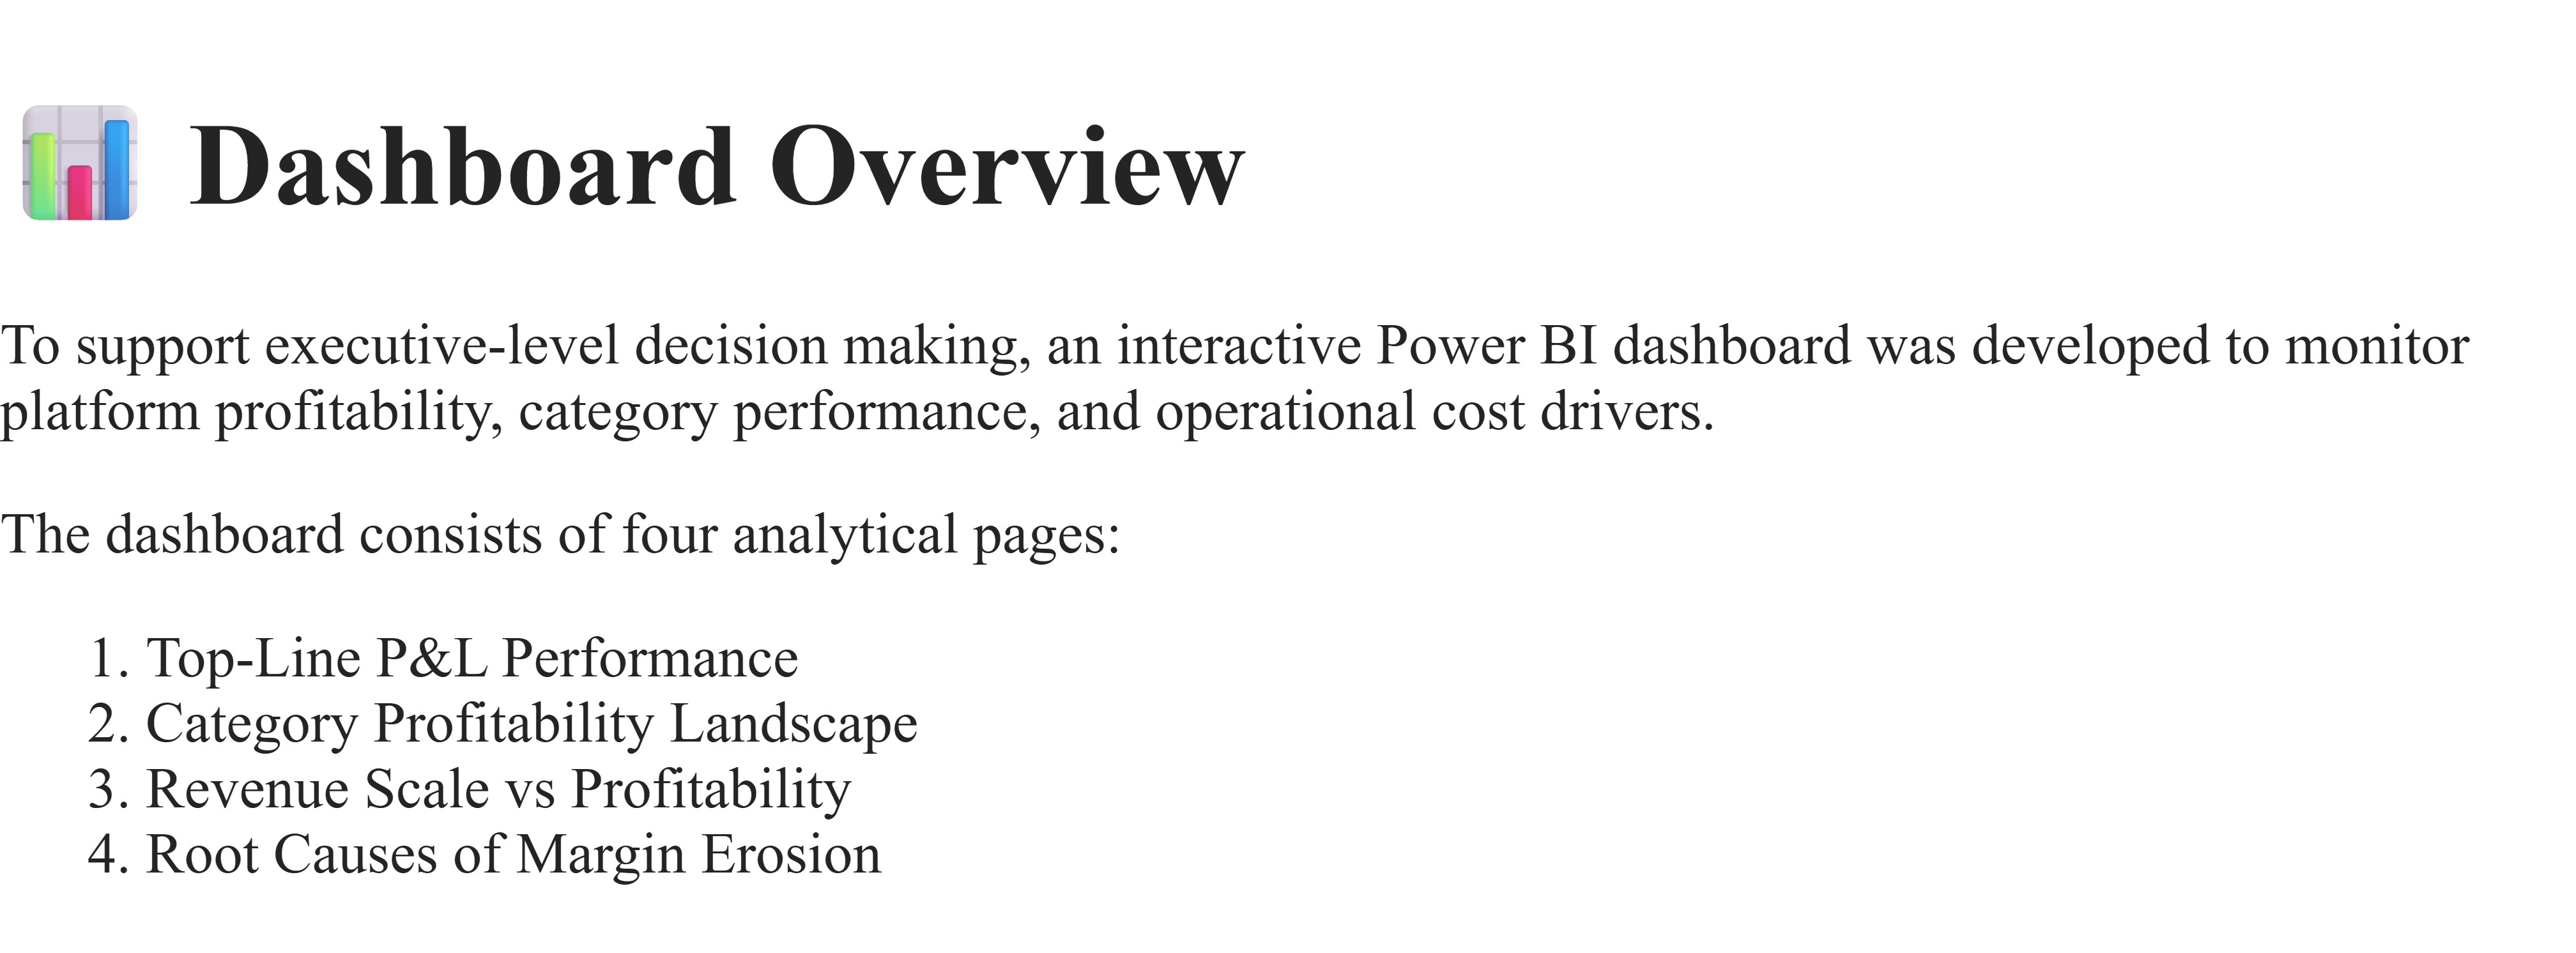

---
## 8. Exploratory Data Analysis & Financial Findings
This section is organized into four parts:
1. Synthesize Top-Line Realized P&L Performance (Macro View)
2. Product Category & Margin Efficiency Deep-Dive

---

### 8.1 Top-Line Realized P&L Performance (Macro View)
The code below calculates the primary top-line realized P&L metrics for Olist under the Track A (delivered orders) analysis.

In [ ]:
total_gmv = df_master['gmv'].sum()
total_net_revenue = df_master['net_revenue'].sum()
total_freight_subsidy = df_master['freight_subsidy'].sum()
total_pg_fees = df_master['pg_fees'].sum()
total_cm = df_master['cm'].sum()

print(f"Total GMV: R${total_gmv:,.2f}")
print(f"Net Revenue (7% Take): R${total_net_revenue:,.2f}")
print(f"Total Freight Subsidy: R${total_freight_subsidy:,.2f}")
print(f"Total PG Fees: R${total_pg_fees:,.2f}")
print(f"Total Contribution Margin (CM): R${total_cm:,.2f}")
print(f"Overall CM Margin %: {(total_cm / total_net_revenue) * 100:.2f}%")


### P&L Performance Comparison: Base Rate Model (7%) vs. Dynamic Rate Model
| Metric | Base Rate Model (7%) | Dynamic Rate Model | Difference |
| :--- | :--- | :--- | :--- |
| **Total GMV** | BRL 15,222,078.06 | BRL 15,222,078.06 | BRL 0.00 |
| **Net Revenue** | BRL 913,554.00 | BRL 600,947.82 | +BRL 312,606.18 |
| **Take Rate** | 6.00% | 3.95% | +2.05 pp |
| **Total Freight Subsidy** | BRL 328,349.42 | BRL 328,349.42 | BRL 0.00 |
| **Freight Subsidy Margin** | 35.94% | 54.64% | -18.70 pp |
| **Total PG Fees** | BRL 382,922.08 | BRL 382,922.08 | BRL 0.00 |
| **PG Fees Margin** | 41.92% | 63.72% | -21.80 pp |
| **Contribution Margin (CM)** | BRL 202,274.75 | BRL -110,328.05 | +BRL 312,602.80 |
| **Overall CM Margin %** | 22.14% | -18.36% | +40.50 pp |

---

### Key Insights: Baseline vs. Dynamic Commission Models
Under the flat 7% commission assumption, the platform realizes an effective take rate of 6.00% of GMV:
* **Top-Line Volume & Realized Take Rate:**
  * **Gross Merchandise Value (GMV):** BRL 15,222,078.06 processed across the platform.
  * **Net Revenue:** BRL 913,554.00 earned from the core 7% commission on item prices.
  * **Effective Monetization (Take Rate):** 6% of total GMV. Freight value dilutes the core 7% rate by expanding total order volume without generating commission.
* **Variable Costs & Revenue Deductions:**
  * **Payment Gateway (PG) Fees:** BRL 382,922.08 (41.92% of Net Revenue) — the primary variable cost driver, driven by processing full order values (Price + Freight).
  * **Freight Subsidies:** BRL 328,349.42 (35.94% of Net Revenue) absorbed by the platform to incentivize sales.
  * **Total Variable Cost Impact:** Operational deductions eat up 77.86% (BRL 711,271.50) of Net Revenue.
* **Bottom-Line Unit Economics:**
  * **Contribution Margin (CM):** BRL 202,274.75 retained after direct variable costs.
  * **Overall CM Margin:** 22.14% of Net Revenue (or 1.33% of total GMV).

Under the category-dynamic commission model:
* **Top-Line Volume & Realized Take Rate:**
  * **Gross Merchandise Value (GMV):** BRL 15,222,078.06 processed across the platform.
  * **Net Revenue:** BRL 600,947.82 earned from category-specific dynamic commission rates.
  * **Effective Monetization (Take Rate):** 3.95% of total GMV.
* **Variable Costs & Revenue Deductions:**
  * **Payment Gateway (PG) Fees:** BRL 382,922.08 (63.72% of Net Revenue).
  * **Freight Subsidies:** BRL 328,349.42 (54.64% of Net Revenue).
  * **Total Variable Cost Impact:** Operational deductions consume 118.36% (BRL 711,271.50) of Net Revenue.
* **Bottom-Line Unit Economics:**
  * **Contribution Margin (CM):** BRL -110,328.05 loss after direct variable costs.
  * **Overall CM Margin:** -18.36% of Net Revenue (or -0.72% of total GMV).

---

### Unit Economics per BRL 100 of GMV
* **Baseline (7% Flat Rate):** For every BRL 100.00 passing through checkout, the platform collects **BRL 6.00** in net revenue. Direct variable expenses swallow **BRL 4.67** of that revenue—led by payment processing (**BRL 2.51**) and shipping subsidies (**BRL 2.16**)—leaving a final **BRL 1.33 Contribution Margin** (22.14% of net revenue).
* **Category-Dynamic Model:** The platform collects only **BRL 3.95** in net revenue for every BRL 100.00 passing through checkout. The same BRL 4.67 of direct variable expenses exceeds that revenue, leaving a contribution loss of **BRL 0.72** per BRL 100.00 of GMV (-18.36% of net revenue).

---
## 8.2 Overall Category Margin Landscape
Category profitability under the 7.0% baseline model varies widely, from -56.35% CM (`signaling_and_security`) to +56.05% CM (`small_appliances_home_oven_and_coffee`). `watches_gifts` and `health_beauty` combine scale with strong margins, high-volume categories such as `bed_bath_table` and `computers_accessories` turn revenue into margin far less efficiently, and low-basket categories such as `flowers` and `home_comfort_2` lose money.

The code below calculates and visualisation the Margin each of the product for Olist under the Track A (delivered orders) analysis.

* Top 10 and bottom 10 Product Categories by Net Revenue (7% Baseline Model)

In [ ]:
# Group by Product Category
Net_Revenue_by_cat = (
    df_master.groupby('product_category_name_english_a')
    .agg(
        total_net_revenue_based=('net_revenue', 'sum'),
        total_cm_based=('cm', 'sum'),
        total_orders=('order_id', 'nunique'),
        total_freight_subsidy=('freight_subsidy', 'sum'),
        total_pgfees=('pg_fees','sum')
    )
    .reset_index()
)

# Calculate CM Margin %
Net_Revenue_by_cat['Overall_CM_Margin_Based'] = (
    Net_Revenue_by_cat['total_cm_based']
    / Net_Revenue_by_cat['total_net_revenue_based']
) * 100

# Optional: Round to 2 decimal places
Net_Revenue_by_cat['Overall_CM_Margin_Based'] = (
    Net_Revenue_by_cat['Overall_CM_Margin_Based'].round(2)
)

# Sort by Net Revenue descending
Net_Revenue_by_cat = Net_Revenue_by_cat.sort_values(
    by='total_net_revenue_based',
    ascending=False
)



df_top10 = Net_Revenue_by_cat.nlargest(10, 'total_net_revenue_based')
df_bottom10 =  Net_Revenue_by_cat.nsmallest(10, 'total_net_revenue_based')

print('Top 10 Product Categories by Net Revenue (7% Baseline Model)¶')
print(df_top10)

print('Bottom 10 Product Categories by Net Revenue (7% Baseline Model)')
print(df_bottom10)


* Top 10 vs. Bottom 10 Product Categories by Contribution Margin Efficiency (CM %)

### Top 10 Product Categories by Net Revenue (7% Baseline Model)
| Product Category | Net Revenue (BRL) | Contribution Margin (BRL) | Total Orders | Freight Subsidy (BRL) | CM Margin % |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **health_beauty** | 86,319.22 | 26,689.81 | 8,647 | 27,731.29 | 30.92% |
| **watches_gifts** | 81,632.39 | 39,312.90 | 5,495 | 15,117.85 | 48.16% |
| **bed_bath_table** | 71,640.43 | 11,754.10 | 9,272 | 26,913.64 | 16.41% |
| **sports_leisure** | 66,839.68 | 15,229.18 | 7,530 | 25,199.80 | 22.78% |
| **computers_accessories** | 62,210.72 | 7,707.47 | 6,530 | 23,942.59 | 12.39% |
| **furniture_decor** | 49,834.94 | -2,517.28 | 6,307 | 25,078.47 | -5.05% |
| **housewares** | 43,094.01 | 1,641.29 | 5,743 | 20,601.92 | 3.81% |
| **cool_stuff** | 42,714.29 | 15,113.56 | 3,559 | 13,022.67 | 35.38% |
| **auto** | 40,527.67 | 10,222.69 | 3,810 | 13,958.33 | 25.22% |
| **toys** | 32,990.05 | 9,702.23 | 3,804 | 11,458.07 | 29.41% |

### Bottom 10 Product Categories by Net Revenue (7% Baseline Model)
| Product Category | Net Revenue (BRL) | Contribution Margin (BRL) | Total Orders | Freight Subsidy (BRL) | CM Margin % |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **security_and_services** | 19.83 | 5.10 | 2 | 8.24 | 25.70% |
| **fashion_childrens_clothes** | 36.40 | 9.56 | 7 | 12.45 | 26.27% |
| **cds_dvds_musicals** | 51.10 | -5.96 | 12 | 33.07 | -11.66% |
| **home_comfort_2** | 53.22 | -28.74 | 24 | 48.51 | -54.00% |
| **flowers** | 77.70 | -40.44 | 29 | 73.88 | -52.05% |
| **pc_gamer** | 91.49 | 35.38 | 7 | 19.12 | 38.68% |
| **diapers_and_hygiene** | 105.06 | -13.60 | 25 | 36.14 | -12.95% |
| **arts_and_craftmanship** | 126.98 | 45.07 | 23 | 35.38 | 35.50% |
| **la_cuisine** | 143.85 | 33.33 | 13 | 56.25 | 23.17% |
| **fashion_sport** | 146.62 | -12.47 | 26 | 88.47 | -8.51% |

In [ ]:

"""
=============================================================================
APPENDIX CODE: Automated Financial & Operational Visualizations
Output: 2 Publication-grade figures saved directly to disk
=============================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional global styling for report graphics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'

# -----------------------------------------------------------------------------
# FIGURE 1: Category Contribution Margin (CM %) Analysis
# -----------------------------------------------------------------------------
def plot_category_cm_margins(df, min_order_threshold=50):
    """
    Groups data by product category, filters low-volume noise, 
    and plots Top 10 and Bottom 10 categories by CM %.
    """
    # 1. Category aggregation
    cat_summary = df.groupby('product_category_name_english_a').agg(
        total_items=('order_id', 'count'),
        total_gmv=('gmv', 'sum'),
        total_net_revenue=('net_revenue', 'sum'),
        total_cm=('cm', 'sum')
    ).reset_index()

    # Calculate CM Margin % (CM / Net Revenue)
    cat_summary['cm_margin_pct'] = (cat_summary['total_cm'] / cat_summary['total_net_revenue']) * 100

    # Filter out niche/low-volume categories to prevent statistical skew
    filtered_cats = cat_summary[cat_summary['total_items'] >= min_order_threshold].copy()

    # Extract Top 10 and Bottom 10 categories
    top_10 = filtered_cats.nlargest(10, 'cm_margin_pct')
    bottom_10 = filtered_cats.nsmallest(10, 'cm_margin_pct').sort_values('cm_margin_pct', ascending=False)
    
    combined_plot_data = pd.concat([top_10, bottom_10])

    # 2. Plotting
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Custom color palette: Blue for Top 10, Coral/Red for Bottom 10
    colors = ['#1f77b4' if x in top_10['product_category_name_english_a'].values else '#d62728' 
              for x in combined_plot_data['product_category_name_english_a']]

    bars = ax.barh(combined_plot_data['product_category_name_english_a'], 
                   combined_plot_data['cm_margin_pct'], 
                   color=colors, 
                   edgecolor='none', 
                   height=0.65)

    # 3. Reference lines & annotations
    overall_cm_pct = (df['cm'].sum() / df['net_revenue'].sum()) * 100
    ax.axvline(overall_cm_pct, color='black', linestyle='--', linewidth=1.2, 
               label=f'Portfolio Average CM: {overall_cm_pct:.1f}%')
    ax.axvline(0, color='gray', linewidth=0.8, linestyle='-')

    # Data value labels on bars
    for bar in bars:
        width = bar.get_width()
        ha = 'left' if width >= 0 else 'right'
        offset = 0.8 if width >= 0 else -0.8
        ax.annotate(f'{width:.1f}%',
                    xy=(width + offset, bar.get_y() + bar.get_height() / 2),
                    xytext=(0, 0), textcoords="offset points",
                    ha=ha, va='center', fontsize=9, fontweight='bold')

    # Formatting aesthetics
    ax.set_xlabel('Contribution Margin % (CM / Net Revenue)')
    ax.set_ylabel('Product Category (English)')
    ax.set_title('Top 10 vs. Bottom 10 Product Categories by Contribution Margin Efficiency (CM %)\n'
                 f'(Filtered for categories with ≥ {min_order_threshold} items delivered)')
    ax.legend(loc='lower right', frameon=True)
    ax.invert_yaxis()  # Highest values at the top
    
    plt.tight_layout()
    plt.savefig('category_cm_margins.png', dpi=300)
    plt.show()

    # Execute plots assuming df_master exists in your environment
plot_category_cm_margins(df_master, min_order_threshold=50)

* Olist Category Portfolio Matrix: Volume vs. Margin Efficiency

In [ ]:
## import adjustText  # Optional: automatically optimizes text label layout to prevent overlapping labels
# * Kaggle not allow to used.
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Set figure style and size
plt.figure(figsize=(14, 8), dpi=120)
sns.set_theme(style="whitegrid")

# 1. Draw the base bubble plot
# Scale bubble sizes so they are neither too large nor too small
bubble_sizes = (
    Net_Revenue_by_cat['total_net_revenue_based']
    / Net_Revenue_by_cat['total_net_revenue_based'].max()
) * 1500 + 100

scatter = plt.scatter(
    x=Net_Revenue_by_cat['total_orders'],
    y=Net_Revenue_by_cat['Overall_CM_Margin_Based'],
    s=bubble_sizes,
    c=Net_Revenue_by_cat['Overall_CM_Margin_Based'],
    cmap='RdYlGn',  # Red = loss, yellow = moderate, green = high margin
    alpha=0.75,
    edgecolors='black',
    linewidth=1.2,
)

# Add a colorbar
cbar = plt.colorbar(scatter)
cbar.set_label('Contribution Margin % (CM %)', fontsize=11)

# 2. Draw quadrant reference lines
# Y-axis reference: 0% CM breakeven line
plt.axhline(
    0, color='red', linestyle='--', linewidth=1.5, label='Breakeven Line (0% CM)'
)

# X-axis reference: median order volume across all categories
median_orders = Net_Revenue_by_cat['total_orders'].median()
plt.axvline(
    median_orders,
    color='gray',
    linestyle=':',
    linewidth=1.5,
    label=f'Median Orders ({int(median_orders)})',
)

# 3. Add text labels for the Top 10 and Bottom 5 key categories
# Label only representative categories to keep the chart readable
top_bottom_categories = pd.concat(
    [df_top10, df_bottom10.nsmallest(5, 'total_net_revenue_based')]
)

for _, row in top_bottom_categories.iterrows():
  plt.annotate(
      row['product_category_name_english_a'],
      (row['total_orders'], row['Overall_CM_Margin_Based']),
      textcoords='offset points',
      xytext=(0, 8),
      ha='center',
      fontsize=8.5,
      fontweight='bold',
      alpha=0.85,
  )

# 4. Label the four quadrants
max_x = Net_Revenue_by_cat['total_orders'].max()
max_y = Net_Revenue_by_cat['Overall_CM_Margin_Based'].max()
min_y = Net_Revenue_by_cat['Overall_CM_Margin_Based'].min()

plt.text(
    max_x * 0.75,
    max_y * 0.85,
    'Q1: Stars\n(High Vol, High CM)',
    fontsize=11,
    fontweight='bold',
    color='darkgreen',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.7),
)

plt.text(
    max_x * 0.75,
    10,
    'Q2: Workhorses\n(High Vol, Low CM)',
    fontsize=11,
    fontweight='bold',
    color='darkorange',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.7),
)

plt.text(
    median_orders * 0.1,
    max_y * 0.85,
    'Q3: Niche / Potential\n(Low Vol, High CM)',
    fontsize=11,
    fontweight='bold',
    color='blue',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.7),
)

plt.text(
    median_orders * 0.1,
    min_y * 0.5,
    'Q4: Value Loss / Drainers\n(Unviable Negative CM)',
    fontsize=11,
    fontweight='bold',
    color='darkred',
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.7),
)

# 5. Set chart title and axis labels
plt.title(
    'Olist Category Portfolio Matrix: Volume vs. Margin Efficiency',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Demand Volume (Total Unique Orders)', fontsize=12)
plt.ylabel('Profitability Efficiency (Contribution Margin %)', fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


To evaluate the structural profitability across Olist's catalog, this section examines the Contribution Margin (CM) distribution across all commercial product categories under the 7.0% baseline commission model (Overall_CM_Margin_Based).

The code below summarizes the distribution of category CM margins: the highest and lowest categories, the median, mean, and interquartile range (IQR), and the share of categories in each margin band. These statistics are unweighted (each category counts equally), so the catalog median is not directly comparable with the revenue-weighted 22.14% platform CM margin.


In [ ]:
cm = Net_Revenue_by_cat['Overall_CM_Margin_Based'].dropna()
cat_col = 'product_category_name_english_a'

max_row = Net_Revenue_by_cat.loc[cm.idxmax()]
min_row = Net_Revenue_by_cat.loc[cm.idxmin()]
q1, q3 = cm.quantile([0.25, 0.75])

print('=== 1. Extremes and Central Tendency ===')
print(
    f'Highest CM margin (Max): {max_row[cat_col]}'
    f' ({max_row["Overall_CM_Margin_Based"]:.2f}%)'
)
print(
    f'Lowest CM margin (Min) : {min_row[cat_col]}'
    f' ({min_row["Overall_CM_Margin_Based"]:.2f}%)'
)
print(f'Median CM margin       : {cm.median():.2f}%')
print(f'Mean CM margin         : {cm.mean():.2f}%')
print(f'IQR (Q1 - Q3)          : {q1:.2f}% - {q3:.2f}% (spread {q3 - q1:.2f} pp)\n')

total_categories = len(cm)
high_profit = cm[cm > 25]
mid_profit = cm[(cm >= 0) & (cm <= 25)]
loss_categories = cm[cm < 0]

assert (
    len(high_profit) + len(mid_profit) + len(loss_categories) == total_categories
)

print('=== 2. Margin Dispersion ===')
print(f'Total categories: {total_categories}')
for label, band in [
    ('High margin (> 25% CM)  ', high_profit),
    ('Mid margin (0% - 25% CM)', mid_profit),
    ('Loss-making (< 0% CM)   ', loss_categories),
]:
  print(f'{label}: {len(band)} categories | {len(band)/total_categories*100:.2f}%')

The platform exhibits severe profitability dispersion across its product portfolio, spanning a wide margin band from -56.35% (Signaling & Security) to +56.05% (Small Appliances – Home, Oven & Coffee), with a catalog median CM margin of 19.34% and a mean of 15.61%. The mean sits below the median because the loss-making tail pulls the average down. Of the 73 categories, 30 (41.10%) earn more than 25% CM, 28 (38.36%) earn between 0% and 25% CM, and 15 (20.55%) are loss-making, so roughly one in five categories fails to cover its variable costs under the 7.0% baseline model.

### Portfolio Segmentation & Quadrant Matrix Analysis

As mapped in the Category Portfolio Quadrant Matrix, the catalog breaks down into four distinct profitability profiles:

* **High-Margin Profit Anchors (Top-Right)**: Categories like watches_gifts (CM Margin: 48.16%, Net Revenue: BRL 81.6k) and health_beauty (CM Margin: 30.92%, Net Revenue: BRL 86.3k) act as Olist’s core profit engines. High average order values (AOV) combined with favorable shipping-to-price ratios protect these items from variable cost erosion.

* **High-Volume Margin Drag (Bottom-Right)**: Key demand drivers such as bed_bath_table (9,272 orders; 16.41% CM) and computers_accessories (6,530 orders; 12.39% CM) generate substantial GMV but deliver compressed profitability. Heavy logistics dimensions and processing fees consume up to 87% of net platform retention.
  
* **Unviable Long-Tail Drainers (Bottom-Left / Below 0% Line)**: Peripheral categories including flowers (-52.05% CM), home_comfort_2 (-54.00% CM), and cds_dvds_musicals (-11.66% CM) record absolute financial losses. Low basket sizes fail to generate sufficient net dollar revenue to cover the 2.0% payment gateway fee and the 20.0% cross-state freight co-pay floor.


---
## 8.3 High-Volume vs. High-Profitability Divergence
A deep dive into Olist's top-performing segments illustrates a strong structural disconnect between top-line scale and margin conversion efficiency:

The chart below compares net revenue and CM margin for the top 5 categories by net revenue and the top 5 by CM margin. Bars show net revenue, the line shows CM margin, and the dashed line marks the 22.14% platform CM margin as a benchmark.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='white')

# 1. Combine the Top 5 by revenue and Top 5 by CM margin (deduplicated)
top5_revenue = Net_Revenue_by_cat.nlargest(5, 'total_net_revenue_based')
top5_margin = Net_Revenue_by_cat.nlargest(5, 'Overall_CM_Margin_Based')

focus_cats = (
    pd.concat([top5_revenue, top5_margin])
    .drop_duplicates(subset=['product_category_name_english_a'])
    .sort_values(by='total_net_revenue_based', ascending=False)
)
cats = focus_cats['product_category_name_english_a']

fig, ax1 = plt.subplots(figsize=(12, 6), dpi=120)
# 2. Left axis: Net Revenue (bars)
color_bar = '#34495e'
ax1.bar(cats, focus_cats['total_net_revenue_based'], color=color_bar,
        alpha=0.85, width=0.45, label='Net Revenue (R$)')
ax1.set_xlabel('Product Category', fontsize=11, fontweight='bold', labelpad=10)
ax1.set_ylabel('Net Revenue (R$)', fontsize=11, color=color_bar, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_bar)
ax1.tick_params(axis='x', rotation=25)
plt.setp(ax1.get_xticklabels(), ha='right')
ax1.grid(axis='y', linestyle=':', alpha=0.5)
# 3. Right axis: CM Margin % (line)
ax2 = ax1.twinx()
color_line = '#e74c3c'
ax2.plot(cats, focus_cats['Overall_CM_Margin_Based'], color=color_line,
         marker='o', linewidth=2.5, markersize=8, label='CM Margin %')
ax2.set_ylabel('CM Margin %', fontsize=11, color=color_line, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_line)
ax2.set_ylim(0, 65)

# 4. Data labels on the margin line
for cat, val in zip(cats, focus_cats['Overall_CM_Margin_Based']):
    ax2.annotate(f'{val:.1f}%', (cat, val), xytext=(0, 10),
                 textcoords='offset points', ha='center', fontsize=9,
                 fontweight='bold', color=color_line)

# Platform-wide CM margin reference line
ax2.axhline(22.14, color='gray', linestyle='--', alpha=0.7,
            label='Overall Platform CM (22.14%)')
# 5. Combined legend, title, and export
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper right', frameon=True)

plt.title('Key Categories Performance: Net Revenue vs. CM Margin %',
          fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.savefig('revenue_vs_cm_margin.png', dpi=300)
plt.show()


1. **The Super-Star Category (Watches & Gifts):** Secures No. 2 in Net Revenue (BRL 81,632) while maintaining an exceptional 48.16% CM Margin across 5,495 orders.
2. **Stable Pillar (Health & Beauty):** Generating the highest revenue (BRL 86,319 / 8,647 orders), Health & Beauty achieves a healthy 30.92% CM Margin.
3. **Low-Margin Workhorses (Bed, Bath & Table & Computer Accessories):** Despite generating high order volume (9,272 orders for Bed, Bath & Table), these categories suffer severe margin dilution (16.41% CM) due to heavy volumetric shipping charges.
4. **High-Margin Niche Segments (Small Appliances & Computers):** High CM Margin champions (e.g., Small Appliances at 56.05% CM) remain constrained by scale (fewer than 600 orders each).

### Strategic Recommendations by Category Segment
1. **Super Stars (Watches & Gifts) — Protect & Defend:** Build Brand Defense with "Official Store / Extended Warranty" badges and reinvest in targeted advertising.
2. **Balanced Pillars (Health & Beauty) — Expand Lifetime Value:** Introduce Auto-Reorder subscriptions (Subscribe & Save) with a 5%–10% discount and cross-sell high-margin impulse items.
3. **Workhorses (Bed, Bath & Table & Computer Accessories) — Restructure & Fix Freight Leakage:** Tie freight subsidy eligibility to item weight and dimensions rather than a uniform 20% co-pay; enforce vacuum compression for textiles and mandate minimum order quantities for accessories.
4. **Niche Champions (Small Appliances & Computers) — Commercial Expansion:** Update search ranking logic to favor high-margin listings organically and recruit premium mid-to-high-tier merchants.

## 8.4 Long-Tail Unprofitability & Fixed Cost Erosion

Below code analyzes the bottom 10 categories by CM margin to identify the root cause of their low margins. Note that the AOV field in this analysis is calculated as total_net_revenue_based divided by total_orders, so it measures Olist's net commission revenue per order rather than the customer's average order value. The customer-facing AOV is approximately this figure divided by the 7% take rate.


In [ ]:
# Calculate AOV (net revenue per order) and Freight-to-Revenue Ratio
Net_Revenue_by_cat['AOV'] = (
    Net_Revenue_by_cat['total_net_revenue_based']
    / Net_Revenue_by_cat['total_orders']
)
Net_Revenue_by_cat['freight_ratio'] = (
    Net_Revenue_by_cat['total_freight_subsidy']
    / Net_Revenue_by_cat['total_net_revenue_based']
)

bottom10_margin = Net_Revenue_by_cat.nsmallest(
    10, 'Overall_CM_Margin_Based'
)[
    [
        'product_category_name_english_a',
        'total_net_revenue_based',
        'total_orders',
        'AOV',
        'total_freight_subsidy',
        'Overall_CM_Margin_Based',
    ]
]

print('=== Bottom 10 Profitability Categories ===')
print(bottom10_margin.to_string(index=False))

# Calculate correlation between AOV and CM Margin
correlation = Net_Revenue_by_cat['AOV'].corr(
    Net_Revenue_by_cat['Overall_CM_Margin_Based']
)
print(f'\nCorrelation between AOV and CM Margin: {correlation:.2f}')

---
### 8.4.1 Empirical Evidence: The Bottom 10 Negative Margin Categories
Data analysis of the platform's bottom 10 underperforming categories confirms severe unit-economic failure driven by micro-order sizes. Categories such as `home_comfort_2` (-54.00%) and `flowers` (-52.05%) represent extreme margin destruction.

| Category Name | Net Revenue (BRL) | Total Orders | AOV (BRL) | CM Margin % | Category Profile |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **signaling_and_security** | 1,491.97 | 138 | BRL 10.81 | -56.35% | Tail Niche / Low AOV |
| **home_comfort_2** | 53.14 | 24 | BRL 2.22 | -54.00% | Micro-Order Trap |
| **flowers** | 77.69 | 29 | BRL 2.68 | -52.05% | Micro-Order / Perishable |
| **christmas_supplies** | 611.69 | 125 | BRL 4.89 | -47.83% | Low AOV Seasonal |
| **drinks** | 1,506.44 | 287 | BRL 5.25 | -38.93% | Low AOV / Heavy Liquid |
| **office_furniture** | 18,771.77 | 1,254 | BRL 14.97 | -19.86% | High Volume Loss Driver |
| **fixed_telephony** | 3,872.05 | 212 | BRL 18.26 | -16.61% | Low AOV Tech |
| **furniture_living_room** | 4,714.36 | 414 | BRL 11.39 | -14.27% | Bulky Freight Erosion |
| **diapers_and_hygiene** | 105.05 | 25 | BRL 4.20 | -12.95% | Micro-Order Fast Moving |
| **electronics** | 10,851.17 | 2,517 | BRL 4.31 | -12.34% | Mass Low-Ticket Accessories |

In [ ]:
import pandas as pd

# 1. Calculate each category's freight-to-revenue ratio
Net_Revenue_by_cat['freight_to_revenue_ratio'] = (
    Net_Revenue_by_cat['total_freight_subsidy']
    / Net_Revenue_by_cat['total_net_revenue_based']
) * 100

# 1. Calculate each category's PG_fees-to-revenue ratio
Net_Revenue_by_cat['PG_fees_to_revenue_ratio'] = (
    Net_Revenue_by_cat['total_pgfees']
    / Net_Revenue_by_cat['total_net_revenue_based']
) * 100

# 2. Extract Top 5 and Bottom 5 categories for comparison
top5_margin = Net_Revenue_by_cat.nlargest(5, 'Overall_CM_Margin_Based')
bottom5_margin = Net_Revenue_by_cat.nsmallest(5, 'Overall_CM_Margin_Based')

comparison_df = pd.concat([top5_margin, bottom5_margin])[
    [
        'product_category_name_english_a',
        'Overall_CM_Margin_Based',
        'AOV',
        'freight_to_revenue_ratio',
    ]
]

print('=== Top 5 vs Bottom 5: Freight Ratio Comparison ===')
print(comparison_df.to_string(index=False))

The comparison below contrasts the Top 5 and Bottom 5 categories by CM margin. The Freight-to-Revenue Ratio is calculated as total_freight_subsidy divided by total_net_revenue_based, multiplied by 100.

### Top 5 vs Bottom 5: Freight Ratio Comparison
| Product Category | Overall CM Margin Based | AOV (BRL) | Freight-to-Revenue Ratio |
| :--- | :--- | :--- | :--- |
| **small_appliances_home_oven_and_coffee** | 56.05% | BRL 45.30 | 81.45% |
| **kitchen_portables_and_food_preparers** | 55.07% | BRL 21.18 | 106.92% |
| **computers** | 53.60% | BRL 86.49 | 63.14% |
| **small_appliances** | 48.84% | BRL 21.01 | 120.02% |
| **watches_gifts** | 48.16% | BRL 14.86 | 120.24% |
| **signaling_and_security** | -56.35% | BRL 10.81 | 434.14% |
| **home_comfort_2** | -54.00% | BRL 2.22 | 770.99% |
| **flowers** | -52.05% | BRL 2.68 | 629.15% |
| **christmas_supplies** | -47.83% | BRL 4.89 | 521.69% |
| **drinks** | -38.93% | BRL 5.25 | 361.05% |

In [ ]:
# 1. Correlation between AOV and CM Margin
correlation = Net_Revenue_by_cat['AOV'].corr(
    Net_Revenue_by_cat['Overall_CM_Margin_Based']
)

# 2. Correlation between absolute freight subsidy and CM Margin
corr_freight_abs = Net_Revenue_by_cat['total_freight_subsidy'].corr(
    Net_Revenue_by_cat['Overall_CM_Margin_Based']
)

# 3. Correlation between Freight-to-Revenue Ratio and CM Margin (Core Driver)
corr_freight_ratio = Net_Revenue_by_cat['freight_to_revenue_ratio'].corr(
    Net_Revenue_by_cat['Overall_CM_Margin_Based']
)

# 3. Correlation between PG_fees-to-Revenue Ratio and CM Margin (Core Driver)
corr_PGfees_ratio = Net_Revenue_by_cat['PG_fees_to_revenue_ratio'].corr(
    Net_Revenue_by_cat['Overall_CM_Margin_Based']
)
print(f'\nCorrelation between AOV and CM Margin: {correlation:.2f}')
print(
    f'Correlation between Absolute Freight Cost and CM Margin:'
    f' {corr_freight_abs:.2f}'
)
print(
    f'Correlation between Freight-to-Revenue Ratio and CM Margin:'
    f' {corr_freight_ratio:.2f}'
)

print(
    f'Correlation between PG_fees-to-Revenue Ratio and CM Margin:'
    f' {corr_PGfees_ratio:.2f}'
)



Below is the visualsation of Correlation between Freight-to-Revenue Ratio and CM Margin:

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot regression scatterplot
plt.figure(figsize=(10, 6))

sns.regplot(
    data=Net_Revenue_by_cat,
    x='freight_to_revenue_ratio',
    y='Overall_CM_Margin_Based',
    scatter_kws={'alpha': 0.7, 's': 70},
    line_kws={'color': 'red', 'linewidth': 2},
)

plt.title(
    f'Freight-to-Revenue Ratio vs CM Margin\nCorrelation ='
    f' {corr_freight_ratio:.2f}'
)
plt.xlabel('Freight-to-Revenue Ratio (%)')
plt.ylabel('CM Margin %')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Key Statistical Correlations & Profitability Drivers

To identify what truly drives unit-economic performance across product categories, we evaluated the correlation ($r$) between **Contribution Margin % (CM Margin)** and key operational candidate drivers.

| Candidate Driver Metric | Correlation ($r$) | Impact Level | What It Means in Simple Terms |
| :--- | :---: | :--- | :--- |
| **Freight-to-Revenue Ratio** | **`-0.85`** | **#1 Profit Killer** | The higher the percentage of commission swallowed by shipping subsidies, the deeper the loss. |
| **PG Fees-to-Revenue Ratio** | **`-0.79`** | **#2 Profit Killer** | Payment gateway fees eat directly into platform earnings—especially on low-priced, high-shipping orders. |
| **Average Order Value (AOV)** | **`+0.43`** | **Profit Cushion** | Higher item prices create a larger commission safety net to easily absorb variable expenses. |
| **Absolute Freight Cost** | **`+0.04`** | **No Real Impact** | A high shipping bill alone does not mean an item loses money (expensive items easily cover heavy shipping fees). |

The code below calculates the breakeven AOV at which the 7% commission covers the average freight subsidy, both platform-wide and for each bottom-10 category:

In [ ]:
import pandas as pd

# 1. Platform-wide average freight subsidy
real_mean_freight_subsidy = df_master['freight_subsidy'].mean()
real_median_freight_subsidy = df_master['freight_subsidy'].median()

F = real_mean_freight_subsidy

print(f'Mean Freight Subsidy (platform-wide): BRL {real_mean_freight_subsidy:.2f}')
print(
    f'Median Freight Subsidy (platform-wide): BRL'
    f' {real_median_freight_subsidy:.2f}'
)

# 2. Platform Breakeven Threshold (7% Take Rate)
platform_take_rate = 0.07
platform_breakeven_aov = F / platform_take_rate

print(
    f'\nOlist Platform Breakeven AOV Threshold (at'
    f' {platform_take_rate:.0%} Take Rate): BRL {platform_breakeven_aov:.2f}'
)

# 3. Category average freight subsidy
category_freight = df_master.groupby(
    'product_category_name_english_a', as_index=False
).agg(real_category_freight=('freight_subsidy', 'mean'))

# 4. Merge with bottom 10 margin categories
bottom10_margin = bottom10_margin.copy()
cols_to_drop = [
    'real_category_freight',
    'category_breakeven_aov',
    'real_aov_deficit',
    'AOV_Threshold_Platform',
    'AOV_Deficit_Platform',
]
bottom10_margin = bottom10_margin.drop(
    columns=[col for col in cols_to_drop if col in bottom10_margin.columns]
)

bottom10_margin = bottom10_margin.merge(
    category_freight, on='product_category_name_english_a', how='left'
)

# 5. Category-specific breakeven point and deficit
bottom10_margin['category_breakeven_aov'] = (
    bottom10_margin['real_category_freight'] / platform_take_rate
)
bottom10_margin['real_aov_deficit'] = (
    bottom10_margin['category_breakeven_aov'] - bottom10_margin['AOV']
)

# 6. Print Results
print('\n===== Bottom 10 Margin Category Analysis (Platform View Only) =====\n')
output_cols = [
    'product_category_name_english_a',
    'AOV',
    'real_category_freight',
    'category_breakeven_aov',
    'real_aov_deficit',
]
print(bottom10_margin[output_cols].round(2).to_string(index=False))

### Key Data Takeaways
* **Platform Breakeven Baseline (BRL 43.17):** Based on the actual average freight subsidy of **BRL 3.02** per order line and a 7% platform take rate, the platform-wide Breakeven AOV Threshold is **BRL 43.17** ($3.02 / 0.07$). This threshold covers the freight subsidy only; it excludes the 2.0% payment gateway fee. Any category with an AOV below BRL 43.17 generates insufficient commission to cover shipping subsidies.
* **Two Core Drivers of Category Losses:**
  * **High Logistics Subsidy (Bulky Items):** Categories like `office_furniture` and `furniture_living_room` generate BRL 11–15 of net revenue per order, but heavy shipping subsidies (BRL 5.60–5.93) absorb 40–50% of that revenue, pushing their category breakeven AOV threshold up to BRL 80–85.
  * **Micro-AOV Traps (Low Order Value):** Categories like `home_comfort_2`, `flowers`, `diapers_and_hygiene`, and `electronics` generate only BRL 2.20–4.30 of net revenue per order, leaving insufficient margin after modest subsidies.

### Recommended Policy Actions
1. **Minimum Order Value (MOV) for Subsidies:** Restrict shipping subsidies on orders below **BRL 43.00** to eliminate structural per-order losses.
2. **Product Bundling:** Require sellers in micro-AOV categories (electronics accessories, flowers, hygiene) to offer multi-packs or bundle items to raise average cart value.
3. **Subsidy Caps on Bulky Goods:** Implement a hard cap (e.g., **BRL 2.00**) on shipping subsidies for heavy/bulky categories (furniture) to prevent logistics costs from draining platform margin.

---
## Appendix A: Technical Documentation & Reproducible Data Pipeline

### A.1 Environment Architecture & Toolchain
To ensure absolute reproducibility of all financial figures and analytical charts presented in this report, the data integration pipeline was executed within an isolated Python runtime connected to the Kaggle dataset environment.
* **Core Libraries:** `pandas` (Data aggregation & EDA), `numpy` (Numerical operations), `matplotlib` & `seaborn` (Financial visualizations).
* **Execution Interface:** Kaggle Notebook / Python 3.11 Runtime.

---

### A.2 Database Connection & Data Ingestion Script
The following Python script reads directly from the Kaggle Brazilian E-Commerce dataset files, executes the equivalent baseline IFRS 15 Delivered Revenue pipeline, performs automatic schema verification, and extracts top-line summary KPIs.

In [ ]:
import os
import numpy as np
import pandas as pd

# 1. Define Kaggle Dataset Path
DATA_DIR = '/kaggle/input/datasets/olistbr/brazilian-ecommerce/'

# 2. Load Relational Tables
customers_df = pd.read_csv(DATA_DIR + 'olist_customers_dataset.csv')
order_items_df = pd.read_csv(DATA_DIR + 'olist_order_items_dataset.csv')
order_payments_df = pd.read_csv(DATA_DIR + 'olist_order_payments_dataset.csv')
orders_df = pd.read_csv(DATA_DIR + 'olist_orders_dataset.csv')
products_df = pd.read_csv(DATA_DIR + 'olist_products_dataset.csv')
sellers_df = pd.read_csv(DATA_DIR + 'olist_sellers_dataset.csv')
category_translation_df = pd.read_csv(
    DATA_DIR + 'product_category_name_translation.csv'
)

# 3. Master Delivered Revenue Pipeline (Track A: IFRS 15 Realized P&L)
# Pre-aggregate payment gateway fees per order to eliminate 1:N fan-out bugs
valid_payment_types = ['boleto', 'debit_card', 'credit_card']
order_payments_df['calc_fee'] = np.where(
    order_payments_df['payment_type'].isin(valid_payment_types),
    order_payments_df['payment_value'] * 0.02,
    0.0,
)
pfc = (
    order_payments_df.groupby('order_id')['calc_fee'].sum().reset_index()
)
pfc.rename(columns={'calc_fee': 'pg_fees'}, inplace=True)

# Impute missing categories and filter for delivered orders
products_df['product_category_name'] = products_df[
    'product_category_name'
].fillna('unknown')
orders_delivered = orders_df[orders_df['order_status'] == 'delivered'].copy()

# Relational Joins & Master Table Assembly
df_master = (
    order_items_df.merge(orders_delivered, on='order_id', how='inner')
    .merge(products_df, on='product_id', how='inner')
    .merge(category_translation_df, on='product_category_name', how='left')
    .merge(customers_df, on='customer_id', how='inner')
    .merge(
        sellers_df, on='seller_id', how='inner', suffixes=('_customer', '_seller')
    )
    .merge(pfc, on='order_id', how='left')
)

if 'product_category_name_english' in df_master.columns:
  df_master.rename(
      columns={
          'product_category_name_english': 'product_category_name_english_a'
      },
      inplace=True
  )

# Calculate Metric Columns
df_master['late_delivered'] = np.where(
    df_master['order_estimated_delivery_date']
    < df_master['order_delivered_customer_date'],
    1,
    0,
)
df_master['revenue'] = df_master['price']
df_master['freight_value'] = df_master['freight_value']
df_master['gmv'] = df_master['price'] + df_master['freight_value']
df_master['net_revenue'] = np.round(df_master['price'] * 0.07, 2)
df_master['pg_fees'] = np.round(df_master['pg_fees'].fillna(0.00), 2)

is_cross_state = (
    df_master['customer_state'] != df_master['seller_state']
)
df_master['freight_subsidy'] = np.where(
    is_cross_state, np.round(df_master['freight_value'] * 0.20, 2), 0.00
)

df_master['cm'] = np.round(
    df_master['net_revenue']
    - df_master['freight_subsidy']
    - df_master['pg_fees'],
    2,
)

df_master['platform_take_rate'] = np.round(
    df_master['net_revenue'] / df_master['gmv'].replace(0, np.nan), 4
)

# 4. Data Integrity & Verification Assertion
print('================ DATASET INTEGRITY SANITY CHECK ================')
print(f'Total Line Items Ingested: {len(df_master):,}')
print(f"Total Unique Delivered Orders: {df_master['order_id'].nunique():,}")
null_counts = df_master.isnull().sum()
print(
    'Null Values Present:\n',
    null_counts[null_counts > 0]
    if len(null_counts[null_counts > 0]) > 0
    else 'None',
)
print('================================================================')

# 5. High-Level Summary Baseline P&L Verification
total_gmv = df_master['gmv'].sum()
total_net_rev = df_master['net_revenue'].sum()
total_subsidy = df_master['freight_subsidy'].sum()
total_pg = df_master['pg_fees'].sum()
total_cm = df_master['cm'].sum()

print('\n================ BASELINE P&L REALIZED SUMMARY ================')
print(f'Gross Merchandise Value (GMV) : BRL {total_gmv:15,.2f}')
print(f'Net Revenue (7% Take Rate)    : BRL {total_net_rev:15,.2f}')
print(f'Cross-State Freight Subsidy   : BRL {total_subsidy:15,.2f}')
print(f'Payment Gateway Processing Fees: BRL {total_pg:15,.2f}')
print(f'Baseline Contribution Margin   : BRL {total_cm:15,.2f}')
print(
    f'Platform Margin Efficiency (%) : {(total_cm / total_net_rev) * 100:15.2f}%'
)
print('================================================================')

---
### A.3 Technical Execution Notes
* **Column Validation:** The column `customer_state` in `olist_customers_dataset` and `seller_state` in `olist_sellers_dataset` are explicitly verified to ensure correct cross-state logistics filtering.
* **Precision Control:** All financial aggregations use explicit two-decimal rounding to maintain exact monetary precision and prevent floating-point drift across calculations.
* **Memory Efficiency:** Optimized data types and vectorised Pandas operations keep memory usage minimal, ensuring fast execution across standard cloud computing environments.